# HD 137010 b — Phase 2: prior predictive analysis

Before adding eccentricity to the transit fit, we ask what the **priors alone** predict, and how much
each prior choice moves the inferred period. Ingredients:

1. the single-transit period prior of Kipping (2018) and its dependence on the assumed intrinsic period distribution,
2. prior predictive distributions of the transit duration $T_{14}$ — why are short periods excluded?,
3. eccentricity priors, including the transit-probability bias towards eccentric orbits,
4. a cheap **rejection-ABC** approximation of the period posterior (course week 10) for every prior combination,
5. **sampler validation**: the Phase 1 emcee chains turn out to under-sample the long-period tail; a
   shape-space parametrisation + prior reweighting, cross-checked with nested sampling (dynesty), fixes this,
6. the resulting period posterior under each period prior, and sensitivity to the upper cut $P_{\max}=2000$ d.

Model code: [`transit.py`](transit.py). Samplers: [`run_circular.py`](run_circular.py) (emcee, physical
parameters), [`run_shape.py`](run_shape.py) (emcee, shape parameters), [`run_dynesty.py`](run_dynesty.py)
(nested sampling, physical parameters). See also [Phase 1](02_circular_baseline.ipynb).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import transit as tr

plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
rng = np.random.default_rng(1)
t, f, P_MIN = tr.load_data()
K = 0.0137  # Rp/R*, pinned by the transit depth

def load_posterior(name):
    r = np.load(f"results/circular_{name}.npz")
    ch = r["chain"][r["chain"].shape[0] // 2:]          # drop burn-in half
    return ch.reshape(-1, ch.shape[-1])

def wquantile(x, w, q):
    i = np.argsort(x)
    c = np.cumsum(w[i])
    return np.interp(q, c / c[-1], x[i])

def summ(x, w=None):
    w = np.ones_like(x) if w is None else w
    lo, med, hi = wquantile(x, w, [0.15865, 0.5, 0.84135])
    return f"{med:.0f} -{med - lo:.0f} +{hi - med:.0f}"

# reference posterior for alpha = 0, e = 0: nested sampling (validated in Sec. 5)
post_ref = np.load("results/dynesty_kipping.npz")["samples"]
d_ref = tr.derived(post_ref)
T14_OBS, T14_SIG = np.median(d_ref["T14_hr"]), np.std(d_ref["T14_hr"])
print(f"observed (posterior): T14 = {T14_OBS:.2f} ± {T14_SIG:.2f} h; P_min = {P_MIN:.1f} d")

observed (posterior): T14 = 9.77 ± 0.20 h; P_min = 64.2 d


## 1. The single-transit period prior

Kipping (2018): if the intrinsic period distribution is $p(P)\propto P^{\alpha}$, then for a planet
observed to transit *exactly once* in a baseline shorter than $P$,
$$
p(P\mid\text{single transit}) \;\propto\; P^{\alpha}\;\cdot\;\underbrace{P^{-2/3}}_{\text{transit prob.}\ \propto R_\*/a}\;\cdot\;\underbrace{P^{-1}}_{\text{window}} \;=\; P^{\alpha-5/3}.
$$
The paper's text ("fitted log-uniformly" plus the Kipping factor) corresponds to $\alpha=-1$ (log-uniform in
$P$, the "uninformative" scale prior) — confirmed by the authors' posterior samples in Sec. 8. Two other
natural choices are $\alpha=0$ (uniform in $P$) and $\alpha=-2/3$ (uniform in $a$). The choice of $\alpha$ is a prior on the *population* of planets, and the data say nothing about it.

$\alpha=0$ (unif. $P$)             : prior Pr(P > 300 d) = 0.2858
$\alpha=-2/3$ (unif. $a$)          : prior Pr(P > 300 d) = 0.1186
$\alpha=-1$ (log-unif. $P$) — paper: prior Pr(P > 300 d) = 0.0736


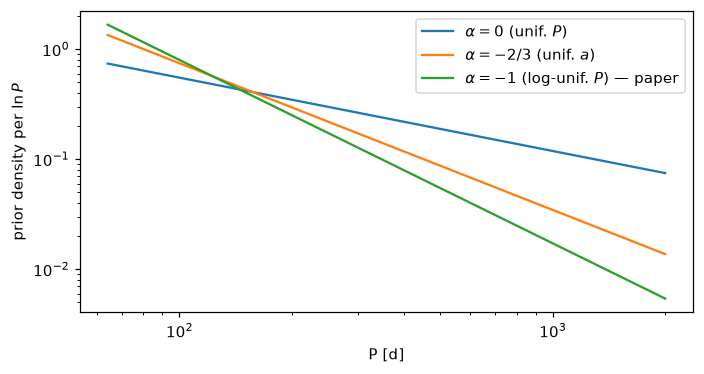

In [2]:
ALPHAS = {0.0: "kipping", -2 / 3: "uniform_a_kipping", -1.0: "loguniform_kipping"}
ALABEL = {0.0: r"$\alpha=0$ (unif. $P$)", -2 / 3: r"$\alpha=-2/3$ (unif. $a$)",
          -1.0: r"$\alpha=-1$ (log-unif. $P$) — paper"}

def sample_P(alpha, n, p_max=tr.P_MAX):
    # inverse-CDF sampling of p(P) ~ P^(alpha - 5/3) on [P_MIN, p_max]
    s = alpha - 5 / 3 + 1
    lo, hi = P_MIN**s, p_max**s
    return (lo + rng.uniform(size=n) * (hi - lo)) ** (1 / s)

P_grid = np.geomspace(P_MIN, tr.P_MAX, 500)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
for a in ALPHAS:
    dens = P_grid ** (a - 5 / 3 + 1)                     # density per unit lnP
    ax.plot(P_grid, dens / np.trapezoid(dens, np.log(P_grid)), label=ALABEL[a])
    frac = np.mean(sample_P(a, 10**6) > 300)
    print(f"{ALABEL[a]:35s}: prior Pr(P > 300 d) = {frac:.4f}")
ax.set(xscale="log", yscale="log", xlabel="P [d]", ylabel=r"prior density per $\ln P$")
ax.legend()
fig.tight_layout()

All three priors put almost no mass at $P\sim$ 1 yr: the prior strongly prefers *short* periods. Any
posterior at $P\sim300$ d is therefore driven entirely by the data (the long duration), and the prior
mainly shapes the **long-period tail**.

## 2. Prior predictive distribution of the transit duration ($e=0$)

Simulate parameters from the prior, $P\sim p(P)$, $\log\rho_\*\sim\mathcal N(0.462,0.041)$, $b\sim U(0,1+k)$,
and compute
$$
T_{14} = \frac{P}{\pi}\arcsin\!\left(\frac{\sqrt{(1+k)^2-b^2}}{a/R_\*}\right)\frac{\sqrt{1-e^2}}{1+e\sin\omega}
\qquad(\sin i\simeq1\text{ for }a/R_\*\gg1).
$$
For $e=0$ the duration is bounded above by its $b=0$ value $\propto P^{1/3}\rho_\*^{-1/3}$, so the
observed $\approx 9.8$ h **sets a hard lower limit on $P$** (≈ 250 d), and larger $b$ needs a longer $P$.

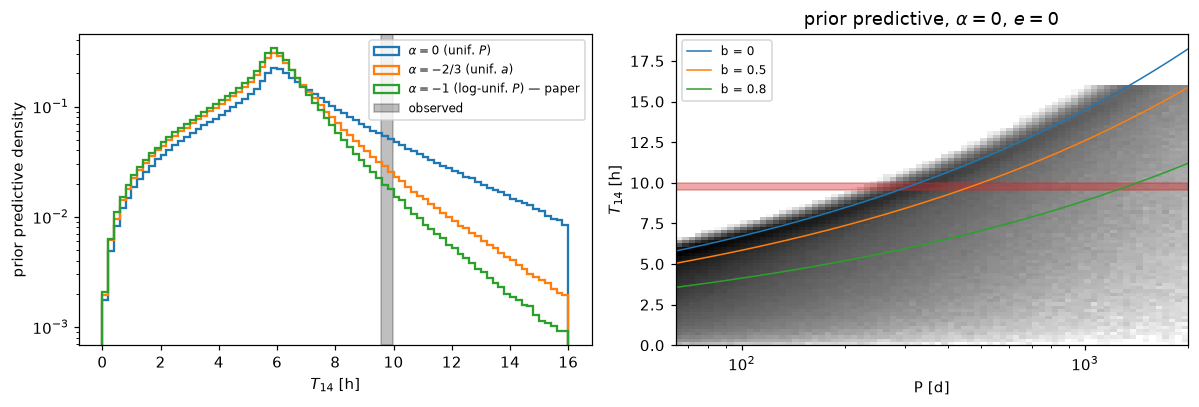

In [3]:
def prior_predictive(alpha, e_prior="circular", n=2_000_000, p_max=tr.P_MAX):
    P = sample_P(alpha, n, p_max)
    log_rho = rng.normal(*tr.LOG_RHO_PRIOR, n)
    b = rng.uniform(0, 1 + K, n)
    w = rng.uniform(0, 2 * np.pi, n)
    e = np.zeros(n) if e_prior == "circular" else np.clip(tr.E_PRIORS[e_prior].rvs(n, random_state=rng), 0, 0.99)
    aR = tr.a_over_rstar(P, log_rho)
    r_tr = aR * (1 - e**2) / (1 + e * np.sin(w))          # star-planet distance at transit [R*]
    # importance weight: eccentric transit-probability factor; drop orbits that graze/enter the star
    wt = tr.transit_prob_factor(e, w) * (r_tr > 2)
    T14 = P / np.pi * np.arcsin(np.clip(np.sqrt((1 + K) ** 2 - b**2) / aR, 0, 1)) / tr.g_factor(e, w) * 24
    return pd.DataFrame(dict(P=P, b=b, e=e, w=w, g=tr.g_factor(e, w), T14=T14, wt=wt / wt.sum()))

pp0 = prior_predictive(0.0)
fig, (a0, a1) = plt.subplots(1, 2, figsize=(11, 3.8))
for a in ALPHAS:
    pp = pp0 if a == 0 else prior_predictive(a)
    a0.hist(pp.T14, bins=np.linspace(0, 16, 81), weights=pp.wt, histtype="step", lw=1.5, density=True,
            label=ALABEL[a])
a0.axvspan(T14_OBS - T14_SIG, T14_OBS + T14_SIG, color="k", alpha=0.25, label="observed")
a0.set(xlabel=r"$T_{14}$ [h]", ylabel="prior predictive density", yscale="log")
a0.legend(fontsize=8)

h = a1.hist2d(pp0.P, pp0.T14, bins=[np.geomspace(P_MIN, 2000, 80), np.linspace(0, 16, 80)],
              cmap="Greys", norm="log")
a1.axhspan(T14_OBS - T14_SIG, T14_OBS + T14_SIG, color="C3", alpha=0.4)
for bb in [0, 0.5, 0.8]:
    T_b = P_grid / np.pi * np.sqrt((1 + K) ** 2 - bb**2) / tr.a_over_rstar(P_grid, tr.LOG_RHO_PRIOR[0]) * 24
    a1.plot(P_grid, T_b, lw=1, label=f"b = {bb}")
a1.set(xscale="log", xlabel="P [d]", ylabel=r"$T_{14}$ [h]", title=r"prior predictive, $\alpha=0$, $e=0$")
a1.legend(fontsize=8, loc="upper left")
fig.tight_layout()

## 3. Eccentricity priors

Priors considered (all with $\omega\sim U(0,2\pi)$):

| name | $p(e)$ | motivation |
|---|---|---|
| `circular` | $\delta(e)$ | paper's assumption |
| `uniform` | $U(0,1)$ | "uninformative" |
| `beta_kipping13` | Beta(0.867, 3.03) | RV-planet population (Kipping 2013) |
| `rayleigh_vaneylen19` | Rayleigh($\sigma=0.049$) | small planets in multi-planet systems (Van Eylen et al. 2019) |

Two effects make eccentricity matter for a single transit:

* **Transit-probability bias.** $p_{\rm tr}\propto (R_\*/a)\,(1+e\sin\omega)/(1-e^2)$: eccentric planets
  transiting near periastron are over-represented among transiting planets (Barnes 2007; Kipping 2014).
  The prior *conditional on a transit* is $p(e,\omega\mid\text{tr})\propto p(e)p(\omega)\,(1+e\sin\omega)/(1-e^2)$.
* **Photo-eccentric effect.** At fixed $\rho_\*$, $T_{14}\propto P^{1/3}/g$ with
  $g=(1+e\sin\omega)/\sqrt{1-e^2}$, so the period implied by a given duration is
  $P = P_{\rm circ}\,g^{3}$ (Dawson & Johnson 2012). Even $g=0.8$ or $1.2$ changes $P$ by a factor of 0.5 or 1.7.

rayleigh_vaneylen19 : 90% interval of P/P_circ = g^3: [0.79, 1.29]
beta_kipping13      : 90% interval of P/P_circ = g^3: [0.45, 7.47]


uniform             : 90% interval of P/P_circ = g^3: [0.44, 1460.72]


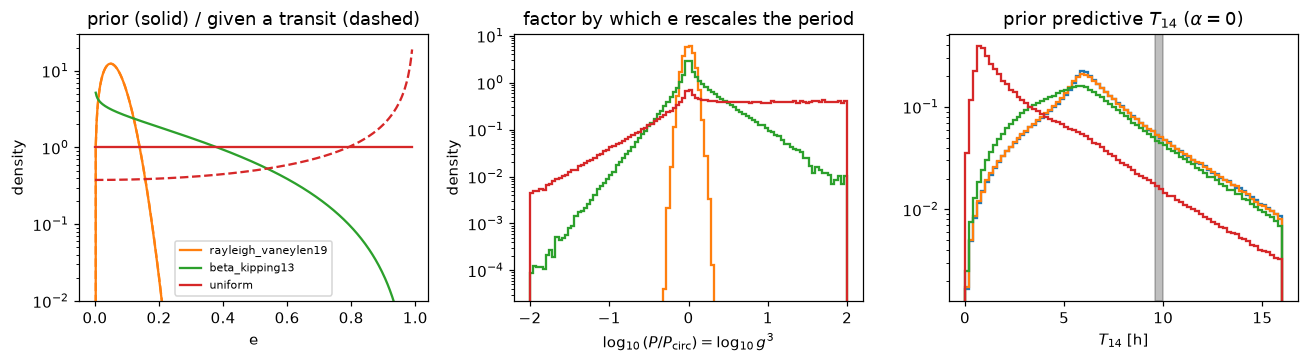

In [4]:
E_LIST = ["circular", "rayleigh_vaneylen19", "beta_kipping13", "uniform"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
egrid = np.linspace(0, 0.99, 400)
for j, name in enumerate(E_LIST[1:]):
    pe = tr.E_PRIORS[name].pdf(egrid)
    # marginal transit-conditioned density: average (1+e sin w)/(1-e^2) over w -> 1/(1-e^2)
    pe_tr = pe / (1 - egrid**2)
    pe_tr /= np.trapezoid(pe_tr, egrid)
    axes[0].plot(egrid, pe, color=f"C{j+1}", label=name)
    axes[0].plot(egrid, pe_tr, color=f"C{j+1}", ls="--")
axes[0].set(xlabel="e", ylabel="density", yscale="log", ylim=(1e-2, 30),
            title="prior (solid) / given a transit (dashed)")
axes[0].legend(fontsize=7)

for j, name in enumerate(E_LIST[1:]):
    pp = prior_predictive(0.0, name, n=500_000)
    axes[1].hist(np.log10(pp.g**3), bins=np.linspace(-2, 2, 101), weights=pp.wt, density=True,
                 histtype="step", lw=1.5, color=f"C{j+1}", label=name)
    lo, hi = wquantile(pp.g.values**3, pp.wt.values, [0.05, 0.95])
    print(f"{name:20s}: 90% interval of P/P_circ = g^3: [{lo:.2f}, {hi:.2f}]")
axes[1].set(xlabel=r"$\log_{10}(P/P_{\rm circ}) = \log_{10} g^3$", ylabel="density", yscale="log",
            title="factor by which e rescales the period")

for j, name in enumerate(E_LIST):
    pp = prior_predictive(0.0, name, n=1_000_000)
    axes[2].hist(pp.T14, bins=np.linspace(0, 16, 81), weights=pp.wt, density=True, histtype="step",
                 lw=1.5, color=f"C{j}", label=name)
axes[2].axvspan(T14_OBS - T14_SIG, T14_OBS + T14_SIG, color="k", alpha=0.25)
axes[2].set(xlabel=r"$T_{14}$ [h]", yscale="log", title=r"prior predictive $T_{14}$ ($\alpha=0$)")
fig.tight_layout()

## 4. Rejection ABC on the transit duration

The light curve constrains the orbit essentially through one summary statistic, $T_{14}$ (plus weak
information on $b$ from the ingress shape). Rejection ABC with the summary $s=T_{14}$ and tolerance
$\epsilon=\sigma_{T_{14}}$: keep prior-predictive draws with $|T_{14}-T_{14}^{\rm obs}|<\epsilon$, weighted
by the transit-probability factor. The accepted draws approximate $p(P\mid T_{14}^{\rm obs})$.

The acceptance probability is itself an ABC estimate of the **marginal likelihood** $p(T_{14}^{\rm obs}\mid\mathcal M)$,
so ratios between prior choices are approximate Bayes factors — how well each prior *predicted* the observed duration.

Comparison: for $\alpha=0$, $e=0$ we compare with the full posterior (nested sampling, Sec. 5). ABC on a
single, not sufficient summary with a hard tolerance is only an approximation — it ignores how the
light-curve shape constrains $b$ and how the $T_{14}$ uncertainty grows towards grazing geometries.

In [5]:
rows, abc = [], {}
for a in ALPHAS:
    for name in E_LIST:
        pp = prior_predictive(a, name)
        acc = (np.abs(pp.T14 - T14_OBS) < T14_SIG).values
        w = pp.wt.values * acc
        abc[(a, name)] = (pp.P.values[acc], pp.wt.values[acc], pp.e.values[acc])
        ess = w.sum() ** 2 / (w**2).sum()
        rows.append(dict(alpha=f"{a:.2f}", e_prior=name, **{"ABC P [d]": summ(pp.P.values[acc], pp.wt.values[acc])},
                         **{"Pr(P<200 d)": np.sum(w[pp.P.values < 200]) / w.sum(),
                            "Pr(P>500 d)": np.sum(w[pp.P.values > 500]) / w.sum(),
                            "p(T14_obs | M) [rel.]": w.sum(), "ESS": int(ess)}))
tab = pd.DataFrame(rows)
tab["p(T14_obs | M) [rel.]"] /= tab["p(T14_obs | M) [rel.]"].iloc[0]
display(tab.round(3))
print("full posterior (dynesty, alpha=0, e=0):  P =", summ(d_ref["P"]))

,alpha,e_prior,ABC P [d],Pr(P<200 d),Pr(P>500 d),p(T14_obs | M) [rel.],ESS
0,0.00,circular,374 -68 +268,0.000,0.262,1.000,40930
1,0.00,rayleigh_vaneylen19,383 -92 +266,0.003,0.272,1.002,41127
2,0.00,beta_kipping13,378 -168 +398,0.144,0.329,0.885,39501
3,0.00,uniform,347 -219 +564,0.281,0.345,0.308,27319
4,-0.67,circular,353 -54 +164,0.000,0.174,0.530,21674
5,-0.67,rayleigh_vaneylen19,354 -76 +173,0.004,0.183,0.529,21813
6,-0.67,beta_kipping13,303 -163 +232,0.272,0.183,0.530,25309
7,-0.67,uniform,201 -112 +302,0.498,0.160,0.224,21552
8,-1.00,circular,346 -51 +140,0.000,0.146,0.365,14958
9,-1.00,rayleigh_vaneylen19,345 -71 +143,0.005,0.148,0.371,15317


full posterior (dynesty, alpha=0, e=0):  P = 384 -79 +323


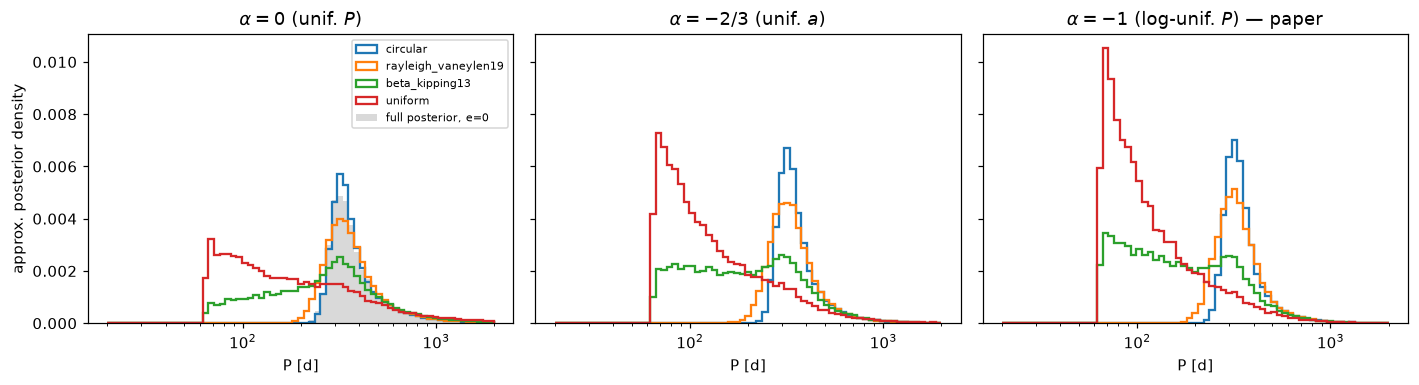

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
bins = np.geomspace(20, 2000, 70)
for ax, a in zip(axes, ALPHAS):
    for j, name in enumerate(E_LIST):
        P, w, _ = abc[(a, name)]
        ax.hist(P, bins=bins, weights=w, density=True, histtype="step", lw=1.5, color=f"C{j}", label=name)
    if a == 0:
        ax.hist(d_ref["P"], bins=bins, density=True, color="k", alpha=0.15, label="full posterior, e=0")
    ax.set(xscale="log", xlabel="P [d]", title=ALABEL[a])
axes[0].set_ylabel("approx. posterior density")
axes[0].legend(fontsize=7)
fig.tight_layout()

## 5. Sampler validation: the long-period tail

The Phase 1 emcee chains (physical parameters $\ln P, b, \log\rho_\*,\dots$) passed the usual diagnostics
($N/\tau>100$, $\hat R\le1.01$). But two checks failed:

* importance-reweighting the $\alpha=0$ chain to $\alpha=-1$ did **not** reproduce the direct $\alpha=-1$ run,
* raising $P_{\max}$ from 2000 to $10^4$ d *decreased* $\Pr(P>1000\,{\rm d})$, which is impossible.

Splitting the post-burn-in chain into quarters shows why: tail quantities fluctuate by large factors between
segments. The long-period tail lives at high impact parameter on a strongly **curved ridge**
($P\propto\rho_\*^{-1}(1-b^2)^{3/2}\,T_{14}^3/\ldots$, i.e. $P$ grows like $(1-b^2)^{-3/2}$ at fixed duration),
which ensemble moves explore poorly — $\tau$ estimated from the bulk is blind to it.

**Fix — shape-space sampling.** For $a/R_\*\gg1$ the transit chord is straight, so the light curve depends
on the orbit only via the chord speed $v=a/(R_\*P)\cdot g(e,\omega)$ and $b$. We sample
$(T_0,\ln v,b,\ln k,u_1,u_2,f_0,\ln\sigma)$ with a flat prior in $\ln v$ ([`run_shape.py`](run_shape.py)), then map
$$P = \frac{G\rho_\*\,g^3}{3\pi v^3}$$
with $\rho_\*$ (and later $e,\omega$) drawn from their priors. Because $|\partial\ln P/\partial\ln v|=3$ is constant,
any prior on $(P,\rho_\*,e,\omega)$ enters as an importance weight $w\propto p(\ln P)\,p_{\rm tr}(e,\omega)$
([`transit.shape_to_physical`](transit.py)). The straight-chord approximation changes $\ln L$ by $<3\times10^{-4}$.

**Arbiter — nested sampling.** dynesty (`rslice`, 1000 live points) in the *original* parametrisation
([`run_dynesty.py`](run_dynesty.py)) is a completely independent sampler.

In [7]:
shape = np.load("results/shape.npz")
sh = shape["chain"][shape["chain"].shape[0] // 2:]
shape_post = sh.reshape(-1, sh.shape[-1])
print(f"shape chain: {shape['chain'].shape[0] * int(shape['thin'])} steps, "
      f"tau_max = {shape['tau_history'][-1, 1:].max():.0f} steps")

def weighted_P(prior, samples=shape_post, p_max=tr.P_MAX, seed=0):
    th, _, _, w = tr.shape_to_physical(samples, prior, p_min=P_MIN, p_max=p_max, n_draws=5, rng=seed)
    return th, w

def tail(P, w=None):
    w = np.full(len(P), 1 / len(P)) if w is None else w
    return np.sum(w[P > 1000])

rows = []
direct = load_posterior("kipping")
for q, (seg_d, seg_s) in enumerate(zip(np.array_split(direct, 4), np.array_split(sh, 4))):
    th, w = weighted_P("kipping", seg_s.reshape(-1, sh.shape[-1]))
    rows.append({"quarter": q + 1,
                 "direct emcee: q84(P)": np.percentile(np.exp(seg_d[:, 1]), 84),
                 "direct emcee: Pr(P>1000)": tail(np.exp(seg_d[:, 1])),
                 "shape + reweight: q84(P)": wquantile(np.exp(th[:, 1]), w, 0.84),
                 "shape + reweight: Pr(P>1000)": tail(np.exp(th[:, 1]), w)})
print("alpha = 0, chain quarters (post burn-in):")
display(pd.DataFrame(rows).set_index("quarter").round(4))

shape chain: 100000 steps, tau_max = 429 steps


alpha = 0, chain quarters (post burn-in):


,direct emcee: q84(P),direct emcee: Pr(P>1000),shape + reweight: q84(P),shape + reweight: Pr(P>1000)
quarter,,,,
1,567.6686,0.0306,695.8774,0.0712
2,579.8997,0.0268,722.1375,0.0749
3,568.5343,0.0174,698.6523,0.0679
4,584.2493,0.0324,741.9302,0.0832


P [d]  Pr(P > 1000 d)  \
prior              sampler                                                
kipping            dynesty                 384 -79 +323           0.083   
                   shape + reweight        392 -84 +325           0.074   
                   direct emcee (Phase 1)  369 -65 +207           0.027   
loguniform_kipping dynesty                 347 -54 +150           0.031   
                   shape + reweight        354 -58 +165           0.024   
                   direct emcee (Phase 1)   334 -43 +80           0.000   

                                           b (3σ upper)  
prior              sampler                               
kipping            dynesty                        0.850  
                   shape + reweight               0.843  
                   direct emcee (Phase 1)         0.821  
loguniform_kipping dynesty                        0.833  
                   shape + reweight               0.823  
                   direct emcee (Phase 1)         0.665

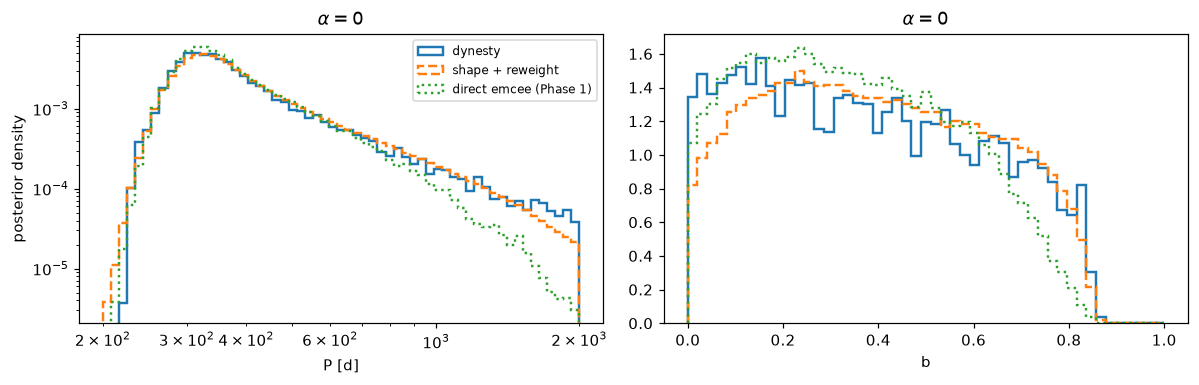

In [8]:
rows, hists = [], {}
for name in ["kipping", "loguniform_kipping"]:
    dy = np.load(f"results/dynesty_{name}.npz")["samples"]
    em = load_posterior(name)
    th, w = weighted_P(name)
    for lab, s, ww in [("dynesty", dy, None), ("shape + reweight", th, w), ("direct emcee (Phase 1)", em, None)]:
        ww = np.full(len(s), 1 / len(s)) if ww is None else ww
        P = np.exp(s[:, 1])
        rows.append({"prior": name, "sampler": lab, "P [d]": summ(P, ww), "Pr(P > 1000 d)": tail(P, ww),
                     "b (3σ upper)": wquantile(s[:, 2], ww, 0.9973)})
        hists[(name, lab)] = (P, s[:, 2], ww)
display(pd.DataFrame(rows).set_index(["prior", "sampler"]).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for lab, ls in [("dynesty", "-"), ("shape + reweight", "--"), ("direct emcee (Phase 1)", ":")]:
    P, b, ww = hists[("kipping", lab)]
    axes[0].hist(P, bins=np.geomspace(200, 2000, 60), weights=ww, density=True, histtype="step", lw=1.6, ls=ls, label=lab)
    axes[1].hist(b, bins=np.linspace(0, 1, 50), weights=ww, density=True, histtype="step", lw=1.6, ls=ls, label=lab)
axes[0].set(xscale="log", yscale="log", xlabel="P [d]", ylabel="posterior density", title=r"$\alpha=0$")
axes[1].set(xlabel="b", title=r"$\alpha=0$")
axes[0].legend(fontsize=8)
fig.tight_layout()

Nested sampling and shape-space sampling agree (to within their Monte Carlo noise); the direct emcee runs
miss a large part of the long-period / high-$b$ tail — by a factor ≈3 in $\Pr(P>1000\,{\rm d})$ for
$\alpha=0$ and by orders of magnitude for $\alpha=-1$. **The Phase 1 chains understate the upper period error.** (The authors' own
chain, run 2000× longer, does not have this problem — Sec. 8.) From here on the
shape-space samples are used, with dynesty as a cross-check.

## 6. Period posterior under each period prior, and the $P_{\max}$ cut

All from the single shape-space chain, by reweighting. The dynesty evidences give the Bayes factor
between $\alpha=0$ and $\alpha=-1$, to compare with the ABC estimate from Sec. 4.

P [d]  mode [d]  \
prior                               P_max                           
$\alpha=0$ (unif. $P$)              2000   392 -84 +325   327.514   
                                    10000  394 -85 +343   327.514   
$\alpha=-2/3$ (unif. $a$)           2000   363 -64 +204   327.514   
                                    10000  363 -64 +208   327.514   
$\alpha=-1$ (log-unif. $P$) — paper 2000   354 -58 +165   319.360   
                                    10000  354 -58 +167   319.360   

                                           Pr(P>1000 d) I [I_earth]  ESS / N  
prior                               P_max                                     
$\alpha=0$ (unif. $P$)              2000          0.074  26-14+11 %    0.892  
                                    10000         0.083  26-14+11 %    0.906  
$\alpha=-2/3$ (unif. $a$)           2000          0.036   29-13+9 %    0.757  
                                    10000         0.038   28-13+9 %    0.761  
$\alpha=-1$ (log-unif. $P$) — paper 2000          0.024   30-12+9 %    0.694  
                                    10000         0.026   30-12+9 %    0.696

paper (Table 2):  P = 355 -59 +200 d, mode ≈ 323 d, I = 0.29 -0.13 +0.11 I_earth
ln Z: alpha=0 1225.48±0.15, alpha=-1 1224.68±0.15  ->  Bayes factor B(0 vs -1) = 2.2
ABC estimate of the same ratio (Sec. 4): 2.7


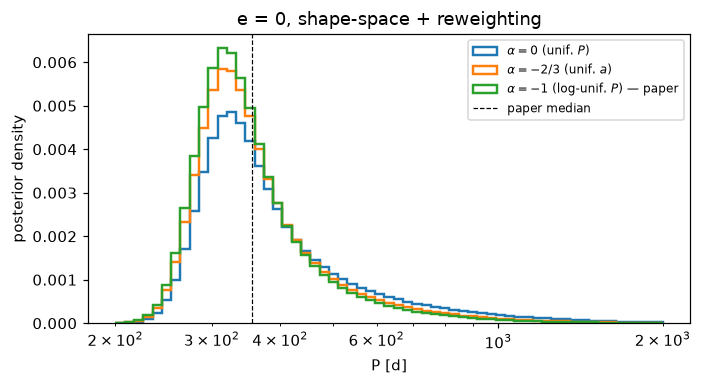

In [9]:
def mode_P(P, w):
    h, e = np.histogram(np.log(P), bins=150, weights=w)
    return np.exp(0.5 * (e[h.argmax()] + e[h.argmax() + 1]))

rows, curves = [], {}
for a, name in ALPHAS.items():
    for p_max in [tr.P_MAX, 1e4]:
        th, w = weighted_P(name, p_max=p_max)
        P = np.exp(th[:, 1])
        d = tr.derived(th, rng=2)
        rows.append({"prior": ALABEL[a], "P_max": int(p_max), "P [d]": summ(P, w), "mode [d]": mode_P(P, w),
                     "Pr(P>1000 d)": tail(P, w), "I [I_earth]": summ(d["insolation"] * 100, w).replace(" ", "") + " %",
                     "ESS / N": 1 / np.sum(w**2) / len(w)})
        if p_max == tr.P_MAX:
            curves[a] = (P, w)
display(pd.DataFrame(rows).set_index(["prior", "P_max"]).round(3))
print("paper (Table 2):  P = 355 -59 +200 d, mode ≈ 323 d, I = 0.29 -0.13 +0.11 I_earth")

lnZ = {n: float(np.load(f"results/dynesty_{n}.npz")["logz"]) for n in ["kipping", "loguniform_kipping"]}
lnZerr = {n: float(np.load(f"results/dynesty_{n}.npz")["logzerr"]) for n in lnZ}
lnB = lnZ["kipping"] - lnZ["loguniform_kipping"]
print(f"ln Z: alpha=0 {lnZ['kipping']:.2f}±{lnZerr['kipping']:.2f}, alpha=-1 {lnZ['loguniform_kipping']:.2f}"
      f"±{lnZerr['loguniform_kipping']:.2f}  ->  Bayes factor B(0 vs -1) = {np.exp(lnB):.1f}")
abc_ratio = tab.loc[0, "p(T14_obs | M) [rel.]"] / tab.loc[8, "p(T14_obs | M) [rel.]"]
print(f"ABC estimate of the same ratio (Sec. 4): {abc_ratio:.1f}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for a, (P, w) in curves.items():
    ax.hist(P, bins=np.geomspace(200, 2000, 60), weights=w, density=True, histtype="step", lw=1.6, label=ALABEL[a])
ax.axvline(355, color="k", ls="--", lw=0.8, label="paper median")
ax.set(xscale="log", xlabel="P [d]", ylabel="posterior density", title="e = 0, shape-space + reweighting")
ax.legend(fontsize=8)
fig.tight_layout()

## 8. Comparison with the authors' posterior samples

The authors of Venner et al. (2026) provided their MCMC posterior (every 10th sample, 50 000 draws;
[`posteriors.csv`](posteriors.csv)). We compare its period distribution with our validated shape-space
posterior reweighted to a range of $\alpha$, without an upper period cut (their chain contains samples above
2000 d), using the Kolmogorov–Smirnov distance between the period CDFs.

,KS distance,P [d],Pr(P>1000),Pr(P>2000),b (3σ)
alpha,,,,,
0.0,0.1401,394 -85 +343,0.0831,0.0095,0.8770
-0.1,0.1230,388 -81 +316,0.0742,0.0080,0.8735
-0.2,0.1065,382 -77 +293,0.0663,0.0067,0.8694
-0.3,0.0906,377 -73 +271,0.0591,0.0057,0.8651
-0.4,0.0751,373 -70 +251,0.0526,0.0047,0.8607
-0.5,0.0601,369 -68 +233,0.0468,0.0040,0.8567
-0.6,0.0466,366 -65 +217,0.0416,0.0033,0.8528
-0.7,0.0343,362 -63 +203,0.0370,0.0028,0.8493
-0.8,0.0223,359 -61 +190,0.0328,0.0023,0.8448


authors' chain:  P = 355 -59 +190  Pr(P>1000) = 0.0323  Pr(P>2000) = 0.0017  b (3σ) = 0.843


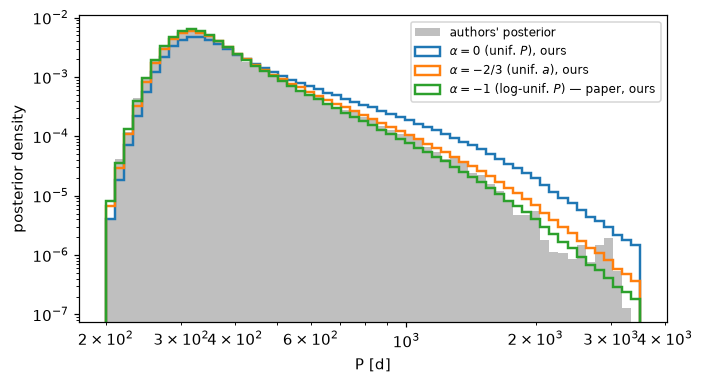

In [10]:
paper = pd.read_csv("posteriors.csv", index_col=0)
P_paper = paper.P.values
th_all, w_all = weighted_P("kipping", p_max=1e5)      # alpha = 0, no upper cut
P_all = np.exp(th_all[:, 1])
order = np.argsort(P_all)
grid = np.sort(P_paper)
ecdf = np.arange(1, len(grid) + 1) / len(grid)

rows = []
for a in np.round(np.arange(0.0, -1.41, -0.1), 2):
    w = w_all * P_all**a
    w /= w.sum()
    ks = np.max(np.abs(np.interp(grid, P_all[order], np.cumsum(w[order])) - ecdf))
    rows.append({"alpha": a, "KS distance": ks, "P [d]": summ(P_all, w), "Pr(P>1000)": tail(P_all, w),
                 "Pr(P>2000)": np.sum(w[P_all > 2000]), "b (3σ)": wquantile(th_all[:, 2], w, 0.9973)})
ks_tab = pd.DataFrame(rows).set_index("alpha")
display(ks_tab.round(4))
print("authors' chain:  P =", summ(P_paper), f" Pr(P>1000) = {np.mean(P_paper > 1000):.4f}",
      f" Pr(P>2000) = {np.mean(P_paper > 2000):.4f}", f" b (3σ) = {np.percentile(paper.b, 99.73):.3f}")

fig, ax = plt.subplots(figsize=(6.5, 3.6))
bins = np.geomspace(200, 3500, 60)
ax.hist(P_paper, bins=bins, density=True, color="k", alpha=0.25, label="authors' posterior")
for a, c in [(0.0, "C0"), (-2 / 3, "C1"), (-1.0, "C2")]:
    w = w_all * P_all**a
    ax.hist(P_all, bins=bins, weights=w, density=True, histtype="step", lw=1.6, color=c, label=ALABEL[a] + ", ours")
ax.set(xscale="log", yscale="log", xlabel="P [d]", ylabel="posterior density")
ax.legend(fontsize=8)
fig.tight_layout()

The authors' chain is matched by $\alpha\approx-0.9$ to $-1$, i.e. $p(P)\propto P^{-8/3}$: sampling
$\log P$ uniformly **and** multiplying by the Kipping factor $P^{-5/3}$ — exactly what the paper's text says.
Their tail ($\Pr(P>1000)$, $\Pr(P>2000)$, $b$ limit) agrees with our validated sampler, so **their chain is
well sampled**; the $P<2000$ d cut mentioned in the paper is not present in these samples (0.17 % above 2000 d,
as expected for $\alpha=-1$ without a cut).

## 7. Summary

**Period prior.** Kipping (2018): $p(P\mid\text{single transit})\propto P^{\alpha-5/3}$, with $\alpha$ the
(unknown) intrinsic period distribution. All choices put only 7–29 % of the prior mass above 300 d, so the
≈1 yr solution is driven by the data (the long duration); the prior mainly shapes the **long-period tail**.

**Prior predictive.** Most prior mass predicts $T_{14}\approx6$ h; the observed 9.8 h sits in the upper tail.
For $e=0$ the $b=0$ duration curve implies $P\gtrsim250$ d, and higher $b$ requires longer $P$.

**Eccentricity (preview of Phase 3).** Conditioning on a transit tilts every $e$ prior towards high $e$ by
$1/(1-e^2)$ — for a uniform prior this diverges. The factor by which $e$ rescales the period,
$g^3$, has a 90 % prior range of [0.79, 1.29] (Rayleigh 0.049), [0.45, 7.5] (Beta, Kipping 2013) and
[0.44, >100] (uniform). Rejection ABC on $T_{14}$ shows the consequence: under the Beta or uniform $e$ priors
14–60 % of the posterior lies at $P<200$ d (eccentric orbits caught near apoastron), while the Rayleigh prior
leaves the circular result essentially unchanged. **The habitable-zone conclusion hinges on the $e$ prior.**

**Approximate evidences.** The ABC acceptance rate estimates $p(T_{14}^{\rm obs}\mid\mathcal M)$: circular and
Rayleigh priors predict the observed duration best, a uniform $e$ prior 3–5× worse. All ratios are modest —
the single transit cannot strongly discriminate between priors. The ABC ratio $\alpha=0$ vs $-1$ (2.7) agrees
with the nested-sampling Bayes factor (2.2).

**Sampler validation — an important correction to Phase 1.** emcee in the physical parametrisation
under-samples the long-$P$/high-$b$ tail despite passing $\tau$ / $\hat R$ diagnostics. Two independent
methods (shape-space sampling + reweighting, and dynesty) agree on the correct posterior. For $\alpha=0$: $P = 392^{+325}_{-84}$ d (dynesty $384^{+323}_{-79}$), $\Pr(P>1000\,{\rm d})\approx8$ %,
$b<0.85$ (3σ). Minor artefact: the shape chain slightly under-weights $b\lesssim0.05$
(hard boundary for the DE moves) — negligible for $P$.

**What did the paper compute?** The authors' posterior samples (Sec. 8) settle it: their result corresponds to
$p(P)\propto P^{-8/3}$ ($\alpha\approx-1$: log-uniform sampling of $P$ *plus* the Kipping factor), and their
chain is well sampled. Our Phase 1 "match" with $\alpha=0$ was a coincidence — an under-sampled $\alpha=0$
chain happens to resemble a well-sampled $\alpha=-1$ posterior. Under a uniform-in-$P$ population prior
($\alpha=0$) the period would instead be $P\approx390^{+325}_{-85}$ d.

**$P_{\max}$ cut.** Raising it from 2000 to $10^4$ d changes the $\alpha=0$ result only mildly
($+325\to+343$ d, $\Pr(P>1000)$ 7.4 → 8.3 %) and is negligible for $\alpha\le-2/3$.

**Robust so far:** the incident flux, $I = 26$–$30\,\%\,I_\oplus$ (±12–14 %) for every period prior at $e=0$.

**Next (Phase 3):** eccentric priors via the *same* shape-space chain (reweighting with $p(e)\,p_{\rm tr}(e,\omega)$),
watching the importance-sampling ESS for broad $e$ priors, plus direct dynesty runs of an eccentric model as a
cross-check. The correlated-noise issue from Phase 1 is still open.